# 01 · Exploratory image analysis

**Project 04 – AI-Powered Image Classification** · dataset: TensorFlow Flowers (5 classes)

This notebook looks at the data *before* any model is trained. Every chart is followed by a written
observation and, where relevant, the decision it led to. It assumes the data pipeline has been run:

```bash
python -m src.data.download && python -m src.data.clean && python -m src.data.split
```

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, torch
from PIL import Image
from torchvision import transforms as T
from src.utils import load_config, load_json, set_seed
from src.data.dataset import train_transform, eval_transform, denormalize

cfg = load_config(); set_seed(cfg["seed"])
sns.set_theme(style="whitegrid")
meta = load_json(ROOT / "reports/dataset_meta.json")
clean = load_json(ROOT / "reports/data_cleaning.json")
man = pd.read_csv(ROOT / "data/processed/manifest.csv")
splits = {s: pd.read_csv(ROOT / f"data/splits/{s}.csv") for s in ["train", "val", "test"]}
CLASSES = sorted(man.label.unique())
FIG = ROOT / "reports/figures"; FIG.mkdir(parents=True, exist_ok=True)
print(json.dumps({k: meta[k] for k in ["name", "url", "licence", "accessed", "total"]}, indent=1))

{
 "name": "TensorFlow Flowers (flower_photos)",
 "url": "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz",
 "licence": "CC BY 2.0 (per-image attribution in LICENSE.txt)",
 "accessed": "2026-10-10",
 "total": 3670
}


## 1 · Sample images from each class

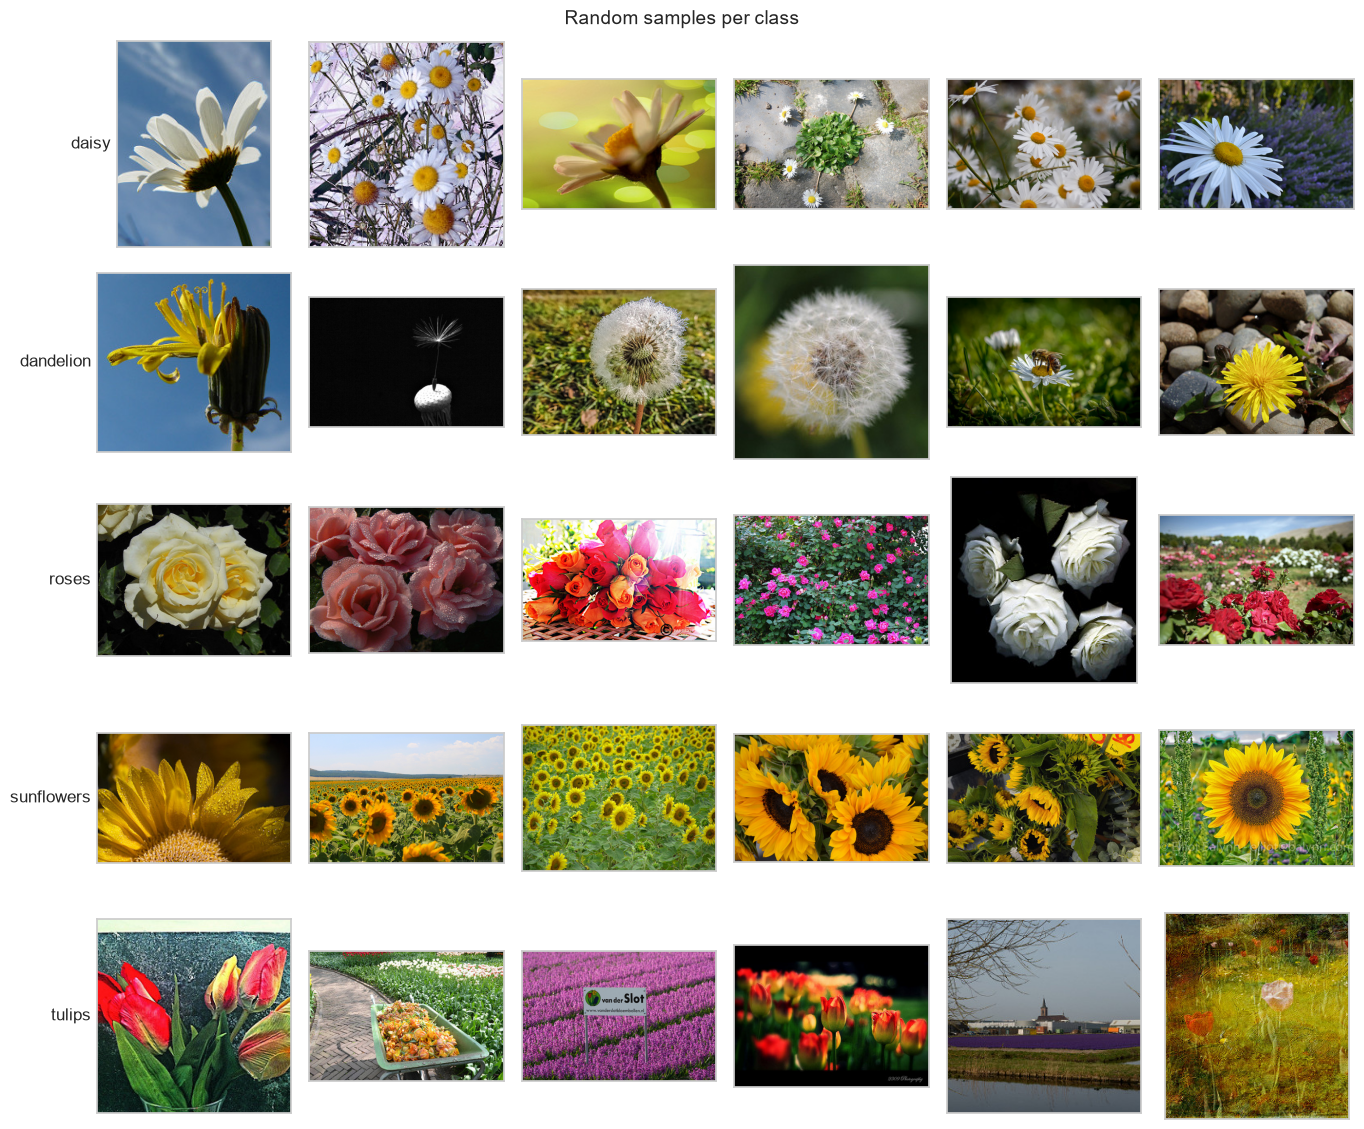

In [2]:
rng = np.random.default_rng(cfg["seed"])
n = 6
fig, axes = plt.subplots(len(CLASSES), n, figsize=(n * 2.3, len(CLASSES) * 2.3))
for r, c in enumerate(CLASSES):
    paths = man[man.label == c].sample(n, random_state=cfg["seed"]).path
    for k, p in enumerate(paths):
        ax = axes[r, k]
        ax.imshow(Image.open(ROOT / p).convert("RGB")); ax.set_xticks([]); ax.set_yticks([])
        if k == 0: ax.set_ylabel(c, fontsize=12, rotation=0, ha="right", va="center")
fig.suptitle("Random samples per class", fontsize=14); fig.tight_layout()
fig.savefig(FIG / "eda_samples.png", dpi=110); plt.show()

**Observation.** The photos are real-world Flickr images rather than studio shots: close-ups, whole fields,
bouquets, macro shots and black backgrounds all appear in the same class. Three things stand out:

* **Dandelion is really two visual classes**: the yellow flower *and* the white seed head ("clock"). The
  seed head shares the colour palette of daisies, so dandelion/daisy confusion is a risk.
* **Tulips contains weakly-labelled scenes**: a wheelbarrow of bulbs, a hyacinth field with a sign,
  a village landscape with a purple strip on the horizon. In several of these the tulips are tiny or absent.
* **Roses vary hugely in colour** (white, pink, red, orange), so colour alone cannot identify the class; the
  model has to learn petal structure.

*Decision:* expect most errors in daisy↔dandelion and roses↔tulips. Grad-CAM is worth building, to check whether
the model looks at the flower or at the context (fields, vases).

## 2 · Image dimensions and aspect ratios

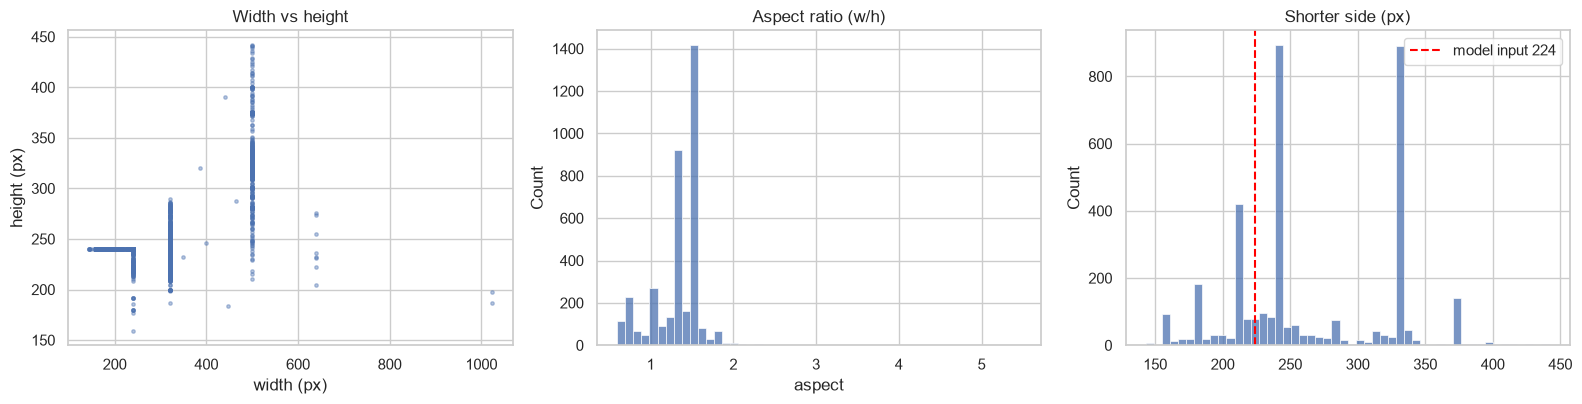

         count    mean     std    min     25%     50%    75%      max
width   3666.0  365.04  116.89  143.0  320.00  320.00  500.0  1024.00
height  3666.0  271.78   51.74  159.0  240.00  240.00  333.0   442.00
aspect  3666.0    1.33    0.29    0.6    1.26    1.34    1.5     5.48
share of images with short side < 224: 26.6%
colour modes: {'RGB': 3666}


In [3]:
man["aspect"] = man.width / man.height
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].scatter(man.width, man.height, s=6, alpha=0.4)
axes[0].set_xlabel("width (px)"); axes[0].set_ylabel("height (px)"); axes[0].set_title("Width vs height")
sns.histplot(man.aspect, bins=50, ax=axes[1]); axes[1].set_title("Aspect ratio (w/h)")
sns.histplot(man[["width", "height"]].min(axis=1), bins=50, ax=axes[2]); axes[2].set_title("Shorter side (px)")
axes[2].axvline(cfg["image"]["size"], color="red", ls="--", label=f"model input {cfg['image']['size']}"); axes[2].legend()
fig.tight_layout(); fig.savefig(FIG / "eda_dimensions.png", dpi=110); plt.show()
print(man[["width", "height", "aspect"]].describe().round(2).T)
print("share of images with short side < 224:", f"{(man[['width','height']].min(axis=1) < 224).mean():.1%}")
print("colour modes:", clean["colour_modes"])

**Observation.** Image sizes are small and fairly uniform. Most files are 240 px or 333 px on the short side
(the Flickr `_m` and `_n` thumbnail sizes), and the aspect ratio clusters around 4:3 / 3:2 landscape. **26.6 % of images
have a short side below 224 px**, so they are slightly upsampled at 224. A handful of outliers are extreme panoramas
(aspect up to 5.5). All files are already 3-channel RGB.

*Decisions:*
* **Input resolution 224×224.** This is the native resolution of the ImageNet-pretrained backbones, and going higher would
  only upsample already-small images further, at 1.5–2× the CPU cost.
* **Resize the short side to 256, then centre-crop to 224 for evaluation.** This keeps the aspect ratio (no squashing).
  The cost is that a centre crop loses the left and right edges of wide images, which is acceptable because subjects are
  usually centred. The panoramas are the exception and will be watched in error analysis.

## 3 · Class distribution

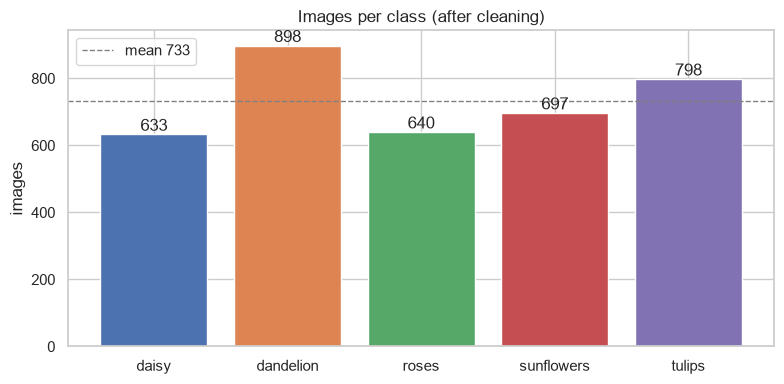

imbalance ratio (max/min): 1.42
inverse-frequency loss weights: {'daisy': 1.158, 'dandelion': 0.816, 'roses': 1.146, 'sunflowers': 1.052, 'tulips': 0.919}


In [4]:
counts = man.label.value_counts().reindex(CLASSES)
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(CLASSES, counts.values, color=sns.color_palette("deep", len(CLASSES)))
ax.bar_label(bars); ax.set_ylabel("images"); ax.set_title("Images per class (after cleaning)")
ax.axhline(counts.mean(), color="grey", ls="--", lw=1, label=f"mean {counts.mean():.0f}"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "eda_class_distribution.png", dpi=110); plt.show()
print(f"imbalance ratio (max/min): {counts.max() / counts.min():.2f}")
print("inverse-frequency loss weights:", (counts.sum() / (len(counts) * counts)).round(3).to_dict())

**Observation.** The classes are mildly imbalanced: dandelion (898) has 1.42× as many images as daisy (633). This is
not severe, but if left uncorrected it gives the largest class a slight prior advantage, and dandelion is
exactly the class most likely to absorb ambiguous daisies.

*Decision:*
1. Use a **stratified** split so every split keeps these proportions.
2. Use **inverse-frequency class weights** in the cross-entropy loss (daisy 1.16 … dandelion 0.82).
3. Report **macro-F1** alongside accuracy, so the smaller classes count equally.

Resampling was rejected: duplicating minority images would encourage memorisation on a small dataset, and the
imbalance is too mild to need it.

## 4 · Data-quality findings from the cleaning step

`src/data/clean.py` decoded every file fully (catching truncation), checked minimum size, hashed every
file (MD5) for exact duplicates and computed a perceptual hash (pHash) to find near-duplicates.

{
 "unreadable_or_truncated": 0,
 "too_small": 0,
 "duplicate_label_conflict": 2,
 "exact_duplicate": 2
}
near-duplicate groups: 15 | images in them: 30


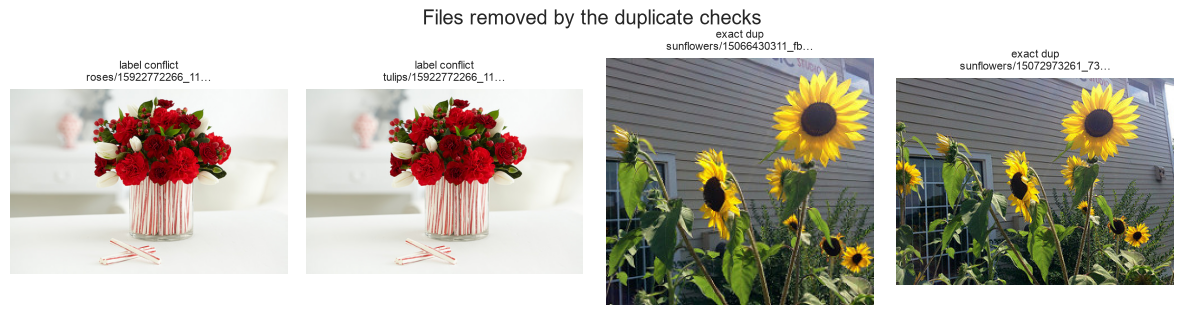

In [5]:
print(json.dumps(clean["removed_counts"], indent=1))
print("near-duplicate groups:", clean["near_duplicate_groups"], "| images in them:", clean["images_in_near_duplicate_groups"])
conf = clean["removed_files"]["duplicate_label_conflict"]
dups = clean["removed_files"]["exact_duplicate"]
show = conf + dups
fig, axes = plt.subplots(1, len(show), figsize=(3 * len(show), 3.2))
for ax, p in zip(np.atleast_1d(axes), show):
    ax.imshow(Image.open(ROOT / p).convert("RGB")); ax.axis("off")
    kind = "label conflict" if p in conf else "exact dup"
    ax.set_title(f"{kind}\n{p.split('/')[-2]}/{p.split('/')[-1][:14]}…", fontsize=8)
fig.suptitle("Files removed by the duplicate checks"); fig.tight_layout(); plt.show()

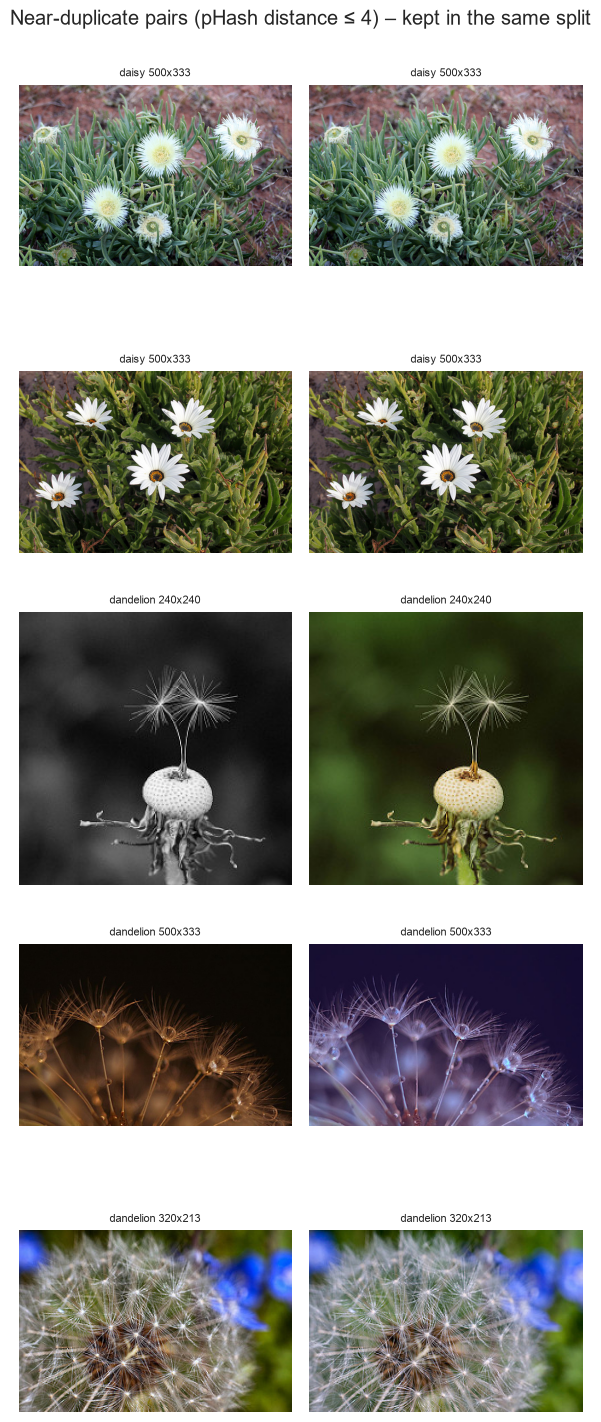

In [6]:
grp = man[man.group.map(man.group.value_counts()) > 1].sort_values("group")
groups = list(grp.groupby("group"))[:5]
fig, axes = plt.subplots(len(groups), 2, figsize=(6, 3 * len(groups)))
for r, (_, g) in enumerate(groups):
    for k, (_, row) in enumerate(g.head(2).iterrows()):
        axes[r, k].imshow(Image.open(ROOT / row.path).convert("RGB")); axes[r, k].axis("off")
        axes[r, k].set_title(f"{row.label} {row.width}x{row.height}", fontsize=8)
fig.suptitle("Near-duplicate pairs (pHash distance ≤ 4) – kept in the same split"); fig.tight_layout()
fig.savefig(FIG / "eda_near_duplicates.png", dpi=110); plt.show()

**Observation.** No file was unreadable, truncated or too small. However, the hash checks found real problems:

* **The same photo appears in both `roses/` and `tulips/`** (byte-identical). At most one of these labels can be correct,
  and with no way to tell which, **both copies were removed**.
* **2 exact duplicates within sunflowers** were removed (one copy kept).
* **15 near-duplicate groups (30 images)** were found with a perceptual hash: re-encoded or colour-graded versions of the
  same shot (for example, a dandelion in greyscale and in colour). These are *kept*, because they are legitimate
  training signal, but each group is **forced into a single split**. Otherwise the test set would contain near-copies of
  training images and overstate accuracy.

Total removed: **4 of 3,670 files (3,666 kept)**. The pipeline also honours `data/exclusions.csv`, for
mislabelled files found later during error analysis (the iterative loop).

## 5 · Augmentation: originals vs transformed

Each transform is shown on its own first so its individual effect is visible, then the full random
training pipeline. Augmentation is applied to the **training split only**.

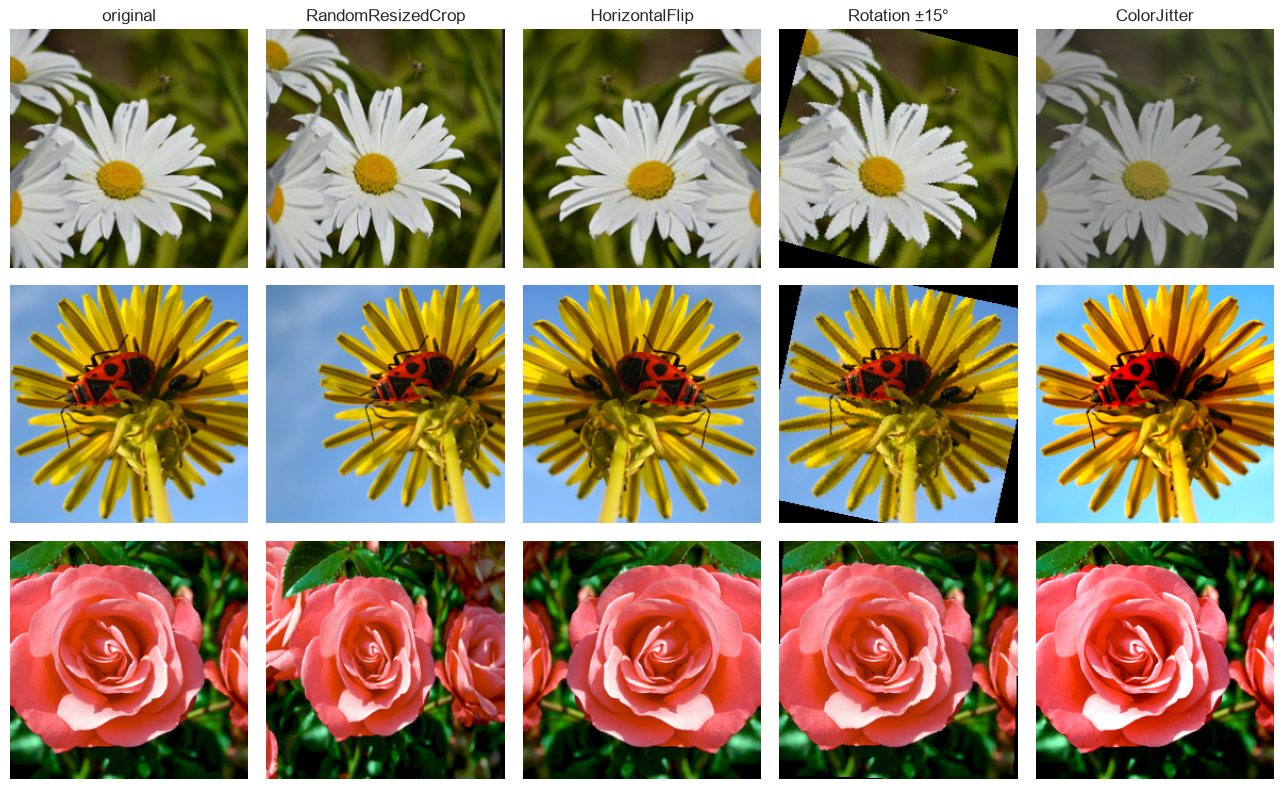

In [7]:
im_cfg = cfg["image"]
single = {
    "RandomResizedCrop": T.RandomResizedCrop(im_cfg["size"], scale=(0.6, 1.0)),
    "HorizontalFlip": T.RandomHorizontalFlip(p=1.0),
    "Rotation ±15°": T.RandomRotation(15),
    "ColorJitter": T.ColorJitter(0.25, 0.25, 0.2, 0.02),
}
base = T.Compose([T.Resize(im_cfg["resize_short"]), T.CenterCrop(im_cfg["size"])])
picks = [man[man.label == c].sample(1, random_state=1).path.iloc[0] for c in CLASSES[:3]]
fig, axes = plt.subplots(len(picks), len(single) + 1, figsize=(2.6 * (len(single) + 1), 2.7 * len(picks)))
for r, p in enumerate(picks):
    img = Image.open(ROOT / p).convert("RGB")
    axes[r, 0].imshow(base(img)); axes[r, 0].set_title("original" if r == 0 else "")
    for k, (name, tf) in enumerate(single.items(), 1):
        torch.manual_seed(r * 10 + k)
        axes[r, k].imshow(tf(base(img)) if name != "RandomResizedCrop" else tf(img))
        if r == 0: axes[r, k].set_title(name)
for ax in axes.ravel(): ax.axis("off")
fig.tight_layout(); fig.savefig(FIG / "eda_augmentation_individual.png", dpi=110); plt.show()

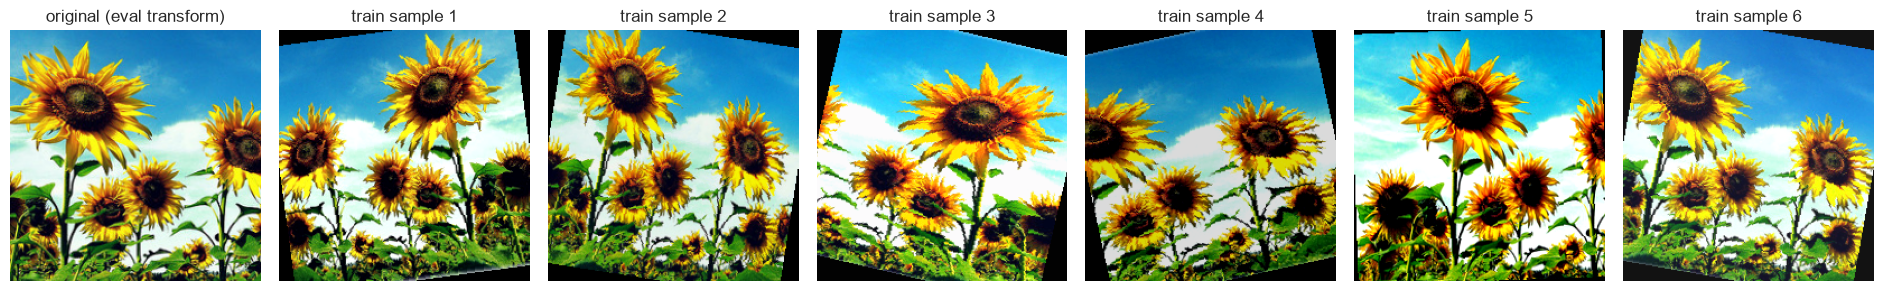

In [8]:
tf = train_transform(cfg)
p = man[man.label == "sunflowers"].sample(1, random_state=3).path.iloc[0]
img = Image.open(ROOT / p).convert("RGB")
fig, axes = plt.subplots(1, 7, figsize=(19, 3))
axes[0].imshow(eval_transform(cfg)(img).permute(1, 2, 0).mul(torch.tensor(im_cfg["std"])).add(torch.tensor(im_cfg["mean"])).clamp(0, 1))
axes[0].set_title("original (eval transform)")
for k in range(1, 7):
    torch.manual_seed(k); axes[k].imshow(denormalize(tf(img), cfg).permute(1, 2, 0)); axes[k].set_title(f"train sample {k}")
for ax in axes: ax.axis("off")
fig.tight_layout(); fig.savefig(FIG / "eda_augmentation_pipeline.png", dpi=110); plt.show()

**Observation and justification of each transform.**

| Transform | Why it is plausible for this data | Risk |
|---|---|---|
| RandomResizedCrop (60–100 %) | flowers are photographed at every distance, from macro to field | too tight a crop could cut out the flower, so the minimum is kept at 60 % |
| Horizontal flip | flowers have no left/right orientation | none |
| Rotation ±15° | handheld camera tilt | **adds black corner wedges** (visible above) |
| Colour jitter (brightness/contrast ±25 %, saturation ±20 %, hue ±2 %) | outdoor lighting varies a lot | hue is a strong class cue (yellow sunflower vs pink rose), so the hue shift is kept tiny |

Vertical flips were rejected: flowers in photos are almost always upright, so a vertical flip would produce unrealistic images.

**Something this chart revealed:** the black corners from rotation appear in many training images and *never* in
validation or test images. That is a small train/serve mismatch. It is left unchanged for the architecture comparison, so that the
comparison is controlled, and tested later as an augmentation ablation.

## 6 · Train vs validation: are the splits comparable?

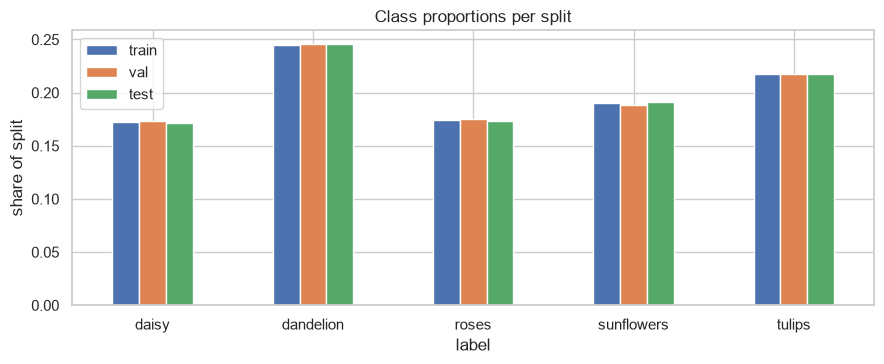

C:\Users\Rashid Ali Soomro\AppData\Local\Temp\ipykernel_8000\2263650681.py:4: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  print(pd.DataFrame({s: d.label.value_counts().reindex(CLASSES) for s, d in splits.items()}).assign(total=lambda x: x.sum(1)))


            train  val  test  total
label                              
daisy         452   91    90    633
dandelion     640  129   129    898
roses         457   92    91    640
sunflowers    498   99   100    697
tulips        570  114   114    798


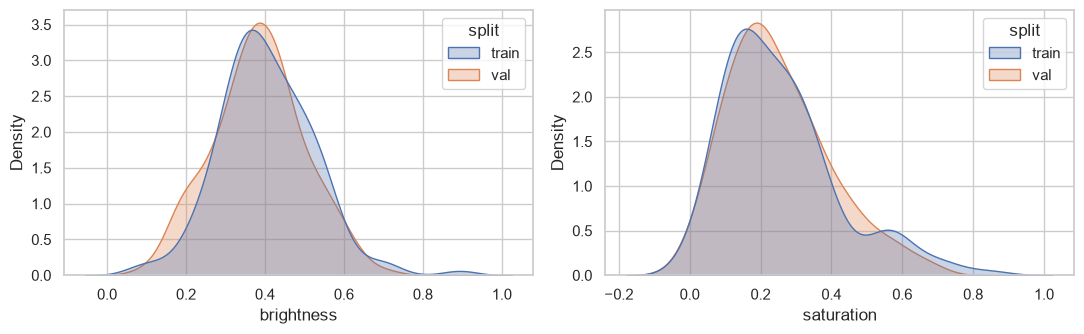

       brightness  saturation
split                        
train       0.403       0.254
val         0.384       0.250


In [9]:
dist = pd.DataFrame({s: d.label.value_counts(normalize=True).reindex(CLASSES) for s, d in splits.items()})
ax = dist.plot.bar(figsize=(9, 3.8), rot=0); ax.set_ylabel("share of split"); ax.set_title("Class proportions per split")
plt.tight_layout(); plt.savefig(FIG / "eda_split_proportions.png", dpi=110); plt.show()
print(pd.DataFrame({s: d.label.value_counts().reindex(CLASSES) for s, d in splits.items()}).assign(total=lambda x: x.sum(axis=1)))

def colour_stats(df, n=150):
    rows = []
    for p in df.sample(min(n, len(df)), random_state=0).path:
        a = np.asarray(Image.open(ROOT / p).convert("RGB").resize((64, 64)), dtype=np.float32) / 255
        rows.append({"brightness": a.mean(), "saturation": (a.max(2) - a.min(2)).mean()})
    return pd.DataFrame(rows)
cs = pd.concat([colour_stats(splits[s]).assign(split=s) for s in ["train", "val"]])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, col in zip(axes, ["brightness", "saturation"]):
    sns.kdeplot(data=cs, x=col, hue="split", ax=ax, common_norm=False, fill=True, alpha=0.3)
fig.tight_layout(); plt.show()
print(cs.groupby("split").mean().round(3))

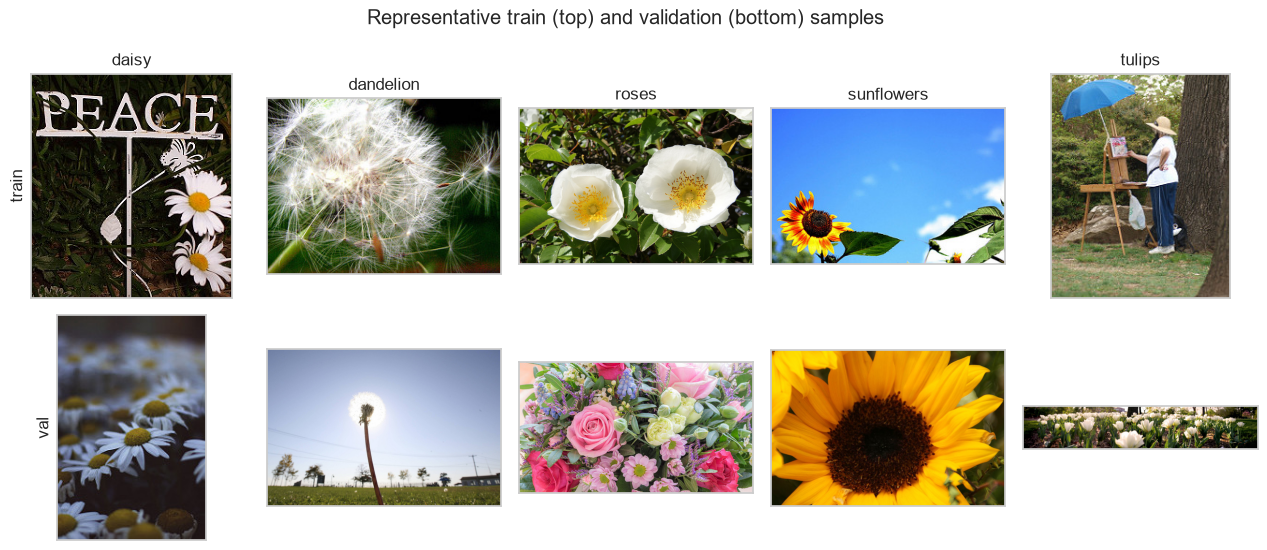

In [10]:
fig, axes = plt.subplots(2, len(CLASSES), figsize=(2.6 * len(CLASSES), 5.6))
for r, s in enumerate(["train", "val"]):
    for k, c in enumerate(CLASSES):
        p = splits[s][splits[s].label == c].sample(1, random_state=7).path.iloc[0]
        axes[r, k].imshow(Image.open(ROOT / p).convert("RGB")); axes[r, k].set_xticks([]); axes[r, k].set_yticks([])
        if r == 0: axes[r, k].set_title(c)
        if k == 0: axes[r, k].set_ylabel(s, fontsize=12)
fig.suptitle("Representative train (top) and validation (bottom) samples"); fig.tight_layout()
fig.savefig(FIG / "eda_train_vs_val.png", dpi=110); plt.show()

**Observation.** The split is 2,617 / 525 / 524 (≈ 71 / 14 / 14 %) with seed 42. It is stratified by class and grouped by
near-duplicate cluster. Class proportions are almost identical across the three splits. Brightness and saturation
distributions of train and validation overlap closely (mean brightness 0.40 vs 0.38), so validation is a fair proxy for
the training distribution.

The random samples also show what the model will have to deal with. The **tulips training sample is a painter at an easel,
with no tulips visible**. The roses sample is a *wild* single-petal rose that looks more like a daisy than a garden rose.
The validation tulips are a very wide panorama that a centre crop will mostly discard. Label noise of this
kind sets a ceiling on achievable accuracy, and these images are expected to show up in the error analysis.

## Summary: what this analysis changed

| Finding | Decision it drove |
|---|---|
| Natural Flickr photos; ImageNet-like content | **Transfer learning** from ImageNet backbones rather than training from scratch (a scratch CNN is kept only as a baseline) |
| Short side mostly 240–333 px | **224 px input**; resize to 256 + centre-crop for evaluation |
| Mild imbalance (1.42×) | Stratified split, **class-weighted loss**, macro-F1 reported |
| Cross-class duplicate, in-class duplicates | Removed (4 files), recorded in `reports/data_cleaning.json` |
| 15 near-duplicate groups | **Group-aware split** to prevent train/test leakage |
| Weak / noisy labels (painter in *tulips*, scenery shots) | Expect an accuracy ceiling below 100 %; check in error analysis; `data/exclusions.csv` hook |
| Dandelion has two visual modes; wild roses resemble daisies | Expect confusion in daisy↔dandelion and roses↔tulips; inspect with Grad-CAM |
| Rotation adds black corners not seen at test time | Planned augmentation ablation |
| Images are low-resolution and colour is a key cue | Hue jitter kept at ±2 %; no vertical flips |